# 01 · Data Exploration

**Goal:** understand the structure, quality and signal in the data before modelling.

**Dataset:** [Diabetes Prediction Dataset](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset) — 100,000 patient records with demographic, comorbidity, lifestyle and laboratory features, and a binary `diabetes` label.

| Column | Description |
|---|---|
| `gender` | Female / Male / Other |
| `age` | Age in years (0.08 – 80) |
| `hypertension`, `heart_disease` | 0/1 comorbidity flags |
| `smoking_history` | never, former, current, not current, ever, No Info |
| `bmi` | Body-mass index (kg/m²) |
| `HbA1c_level` | Glycated haemoglobin (%) — ~3-month average blood glucose |
| `blood_glucose_level` | Blood glucose (mg/dL) |
| `diabetes` | **Target** — 1 = diabetes |

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)

from src.config import FIGURES_DIR, MODELS_DIR, REPORTS_DIR, TARGET
from src.evaluation import save_fig

In [2]:
from src.data_preparation import load_raw_data, clean_data, add_engineered_features, add_clinical_bins

raw = load_raw_data()
print(raw.shape)
raw.head()

(100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0000,0,1,never,25.1900,6.6000,140,0
1,Female,54.0000,0,0,No Info,27.3200,6.6000,80,0
2,Male,28.0000,0,0,never,27.3200,5.7000,158,0
3,Female,36.0000,0,0,current,23.4500,5.0000,155,0
4,Male,76.0000,1,1,current,20.1400,4.8000,155,0


## 1. Data quality

In [3]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
})
print(f"Duplicate rows: {raw.duplicated().sum():,}")
quality

Duplicate rows: 3,854


,dtype,missing,unique
gender,str,0,3
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,str,0,6
bmi,float64,0,4247
HbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2


In [4]:
for col in ["gender", "smoking_history"]:
    print(raw[col].value_counts(), "\n")
print("Diabetes among gender == 'Other':", raw.loc[raw.gender == "Other", TARGET].value_counts().to_dict())

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64 

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64 

Diabetes among gender == 'Other': {0: 18}


**Findings**

* No missing values in the conventional sense, but **`smoking_history = "No Info"` (~36%)** is effectively a missing-value category. We keep it as its own level rather than imputing, because "not recorded" may itself carry information.
* **3,854 exact duplicate rows** are dropped.
* `gender == "Other"` has only **18 rows, none with diabetes**. It is too small to learn from, so these rows are removed (documented as a limitation).
* `age` has a minimum of 0.08 — infants are present, which matters when interpreting age effects.

In [5]:
df = add_clinical_bins(add_engineered_features(clean_data(raw)))
print(f"Rows after cleaning: {len(df):,}  (removed {len(raw) - len(df):,})")
print(f"Diabetes prevalence: {df[TARGET].mean():.2%}")
df.describe().T

Rows after cleaning: 96,128  (removed 3,872)
Diabetes prevalence: 8.82%


,count,mean,std,min,25%,50%,75%,max
age,96128.0000,41.7966,22.4633,0.0800,24.0000,43.0000,59.0000,80.0000
hypertension,96128.0000,0.0776,0.2676,0.0000,0.0000,0.0000,0.0000,1.0000
heart_disease,96128.0000,0.0408,0.1979,0.0000,0.0000,0.0000,0.0000,1.0000
bmi,96128.0000,27.3215,6.7678,10.0100,23.4000,27.3200,29.8600,95.6900
HbA1c_level,96128.0000,5.5326,1.0732,3.5000,4.8000,5.8000,6.2000,9.0000
blood_glucose_level,96128.0000,138.2180,40.9112,80.0000,100.0000,140.0000,159.0000,300.0000
diabetes,96128.0000,0.0882,0.2836,0.0000,0.0000,0.0000,0.0000,1.0000
age_bmi,96128.0000,1194.3596,714.7488,0.8840,616.4600,1199.6800,1721.1600,7100.8000
glucose_hba1c,96128.0000,772.2489,312.6099,280.0000,549.0000,754.0000,928.0000,2700.0000
prediabetes_flag,96128.0000,0.4137,0.4925,0.0000,0.0000,0.0000,1.0000,1.0000


## 2. Target distribution

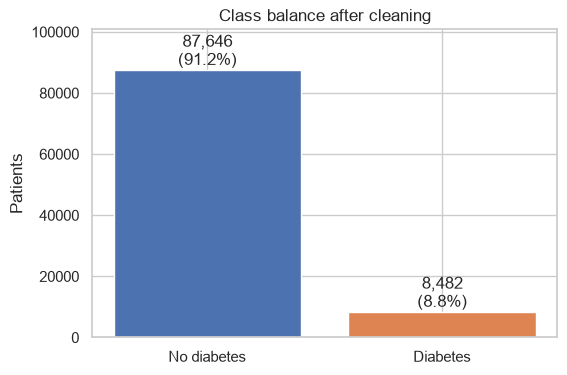

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df[TARGET].value_counts().sort_index()
ax.bar(["No diabetes", "Diabetes"], counts.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set(ylabel="Patients", title="Class balance after cleaning", ylim=(0, counts.max() * 1.15))
save_fig(fig, FIGURES_DIR / "eda_target_distribution.png");

Only **~8.8%** of patients have diabetes. Accuracy is therefore a misleading metric (predicting "no diabetes" for everyone already scores 91%), so modelling focuses on **ROC-AUC, PR-AUC, sensitivity, precision and calibration**.

## 3. Laboratory markers

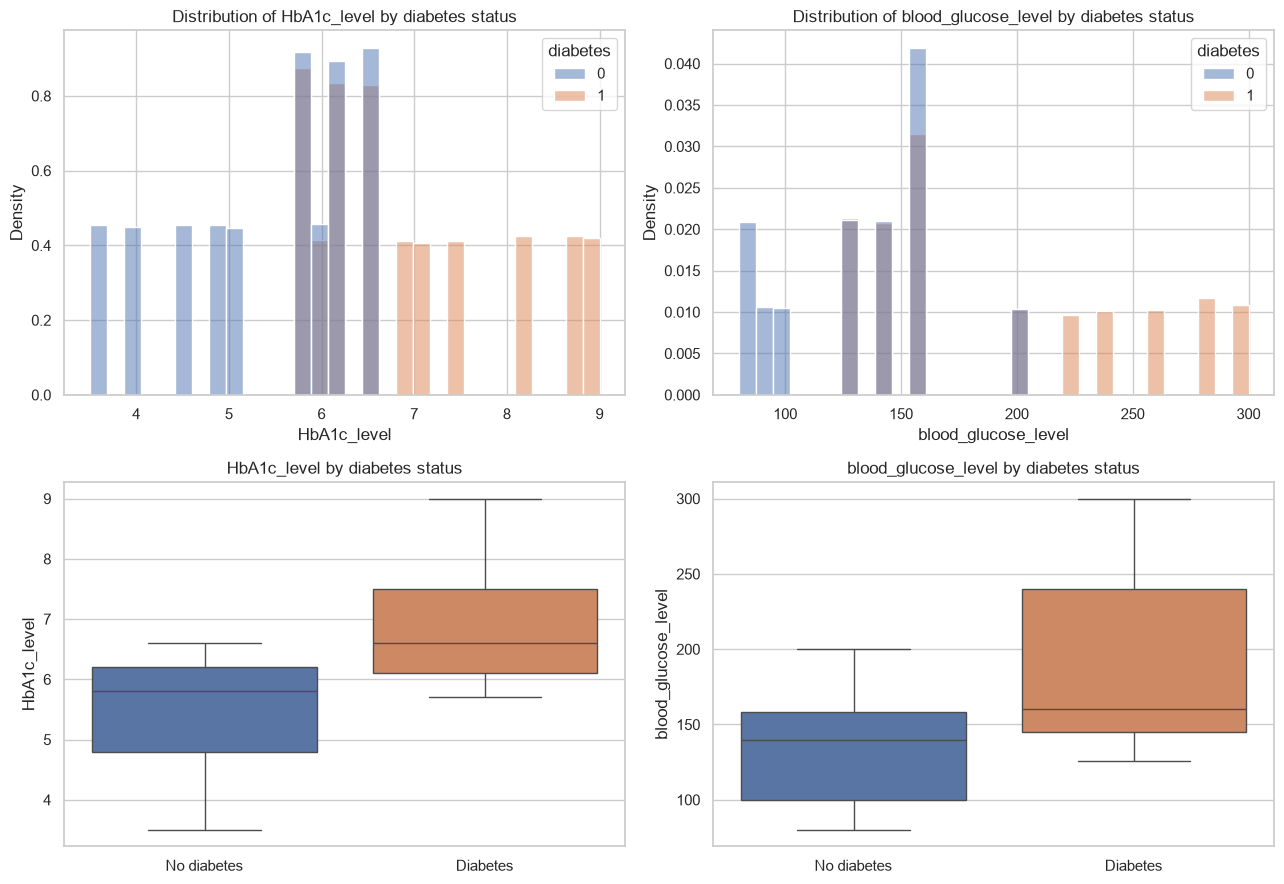

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, (ax_hist, ax_box) in zip(["HbA1c_level", "blood_glucose_level"], [axes[:, 0], axes[:, 1]]):
    sns.histplot(data=df, x=col, hue=TARGET, stat="density", common_norm=False,
                 discrete=False, bins=30, ax=ax_hist, palette=["#4C72B0", "#DD8452"])
    ax_hist.set_title(f"Distribution of {col} by diabetes status")
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax_box, palette=["#4C72B0", "#DD8452"], hue=TARGET, legend=False)
    ax_box.set_xticks([0, 1], ["No diabetes", "Diabetes"])
    ax_box.set(xlabel="", title=f"{col} by diabetes status")
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "eda_lab_markers.png");

In [8]:
df.groupby(TARGET)[["age", "bmi", "HbA1c_level", "blood_glucose_level"]].median().rename(
    index={0: "No diabetes", 1: "Diabetes"})

,age,bmi,HbA1c_level,blood_glucose_level
diabetes,,,,
No diabetes,40.0000,27.3200,5.8000,140.0000
Diabetes,62.0000,29.9850,6.6000,160.0000


Both markers are recorded at a small number of discrete values (18 HbA1c levels, 18 glucose levels), which suggests the data are partly **synthetic or rounded**. Diabetes prevalence by clinical category reveals something important:

In [9]:
lab_tables = {
    col: df.groupby(col, observed=True)[TARGET].agg(patients="size", diabetes_rate="mean")
    for col in ["hba1c_cat", "glucose_cat"]
}
for col, t in lab_tables.items():
    display(t)

print("Diabetes rate when HbA1c >= 6.8:", round(df.loc[df.HbA1c_level >= 6.8, TARGET].mean(), 3))
print("Diabetes rate when glucose >= 220:", round(df.loc[df.blood_glucose_level >= 220, TARGET].mean(), 3))

,patients,diabetes_rate
hba1c_cat,,
normal (<5.7),36258,0.0000
prediabetes (5.7-6.4),39770,0.0831
diabetes (>=6.5),20100,0.2577


,patients,diabetes_rate
glucose_cat,,
normal (<100),20236,0.0000
prediabetes (100-125),6774,0.0000
high (>=126),69118,0.1227


Diabetes rate when HbA1c >= 6.8: 1.0
Diabetes rate when glucose >= 220: 1.0


**Key insight — the label is partly determined by the lab values.**

* **No one** with HbA1c < 5.7% or glucose < 126 mg/dL is labelled diabetic.
* **Everyone** with HbA1c ≥ 6.8% or glucose ≥ 220 mg/dL is labelled diabetic.

These are essentially the clinical diagnostic thresholds, so a model with access to HbA1c and glucose is partly *re-discovering the diagnostic rule* rather than predicting future disease. This explains the very high discrimination seen later, and motivates the **"no-lab" ablation** in notebook 03, which estimates risk from demographics and history alone (a more realistic pre-screening scenario).

## 4. Demographic and clinical risk factors

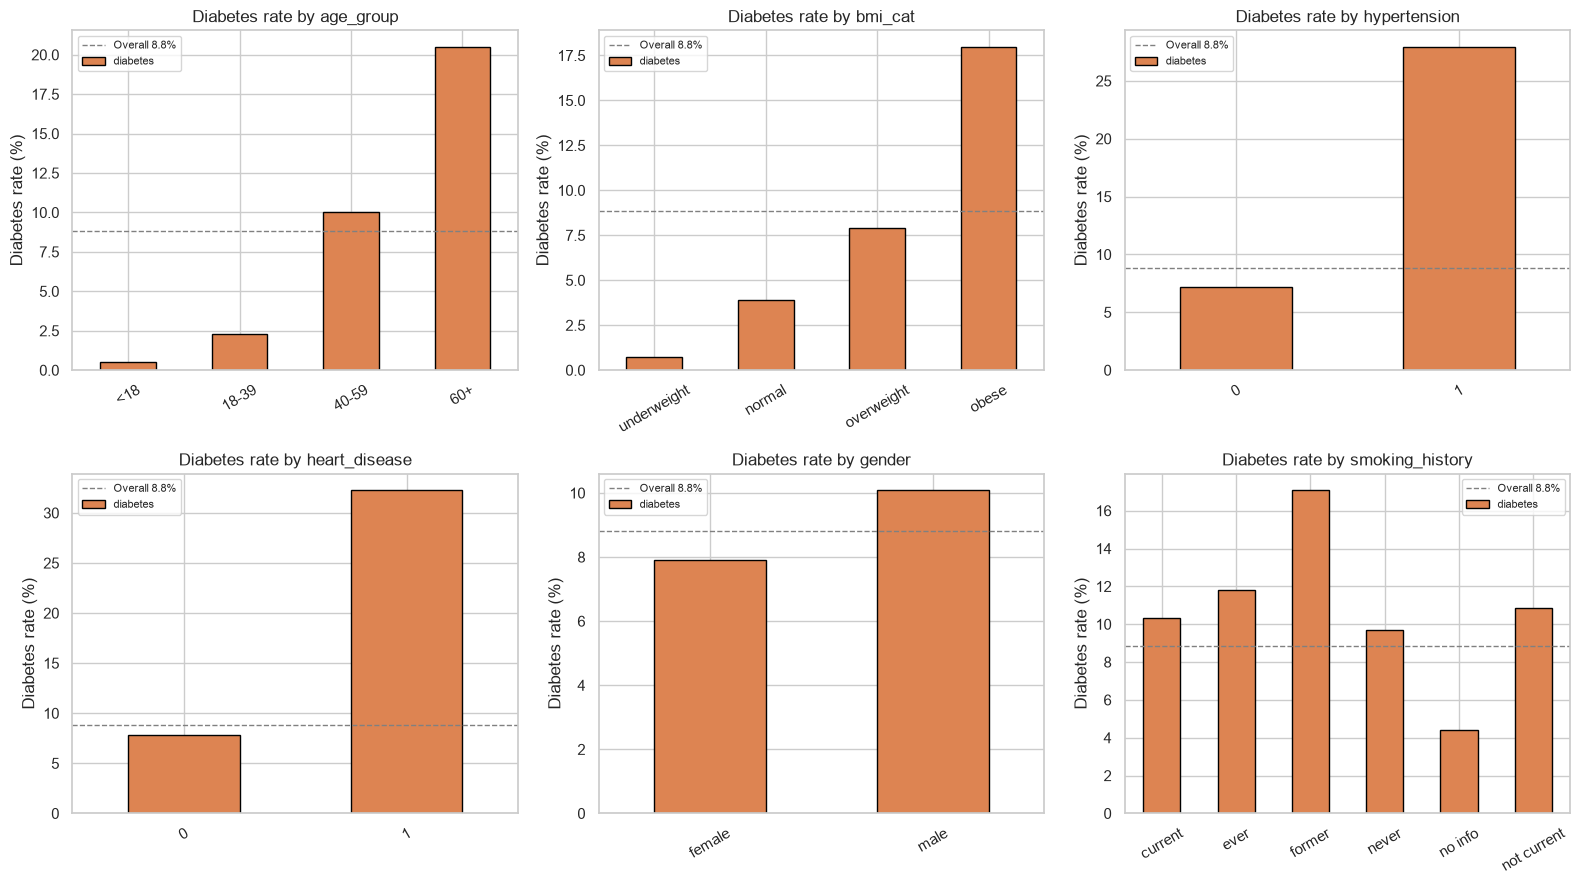

In [10]:
factors = ["age_group", "bmi_cat", "hypertension", "heart_disease", "gender", "smoking_history"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
overall = df[TARGET].mean()
for col, ax in zip(factors, axes.ravel()):
    rates = df.groupby(col, observed=True)[TARGET].mean().mul(100)
    rates.plot.bar(ax=ax, color="#DD8452", edgecolor="black")
    ax.axhline(overall * 100, ls="--", color="grey", lw=1, label=f"Overall {overall:.1%}")
    ax.set(title=f"Diabetes rate by {col}", xlabel="", ylabel="Diabetes rate (%)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "eda_risk_factors.png");

* **Age** is the strongest non-lab factor: prevalence rises from **0.5%** in under-18s to **~20%** in the 60+ group. A few young diabetics appear as outliers and may represent type 1 diabetes.
* **BMI:** prevalence increases monotonically from underweight (0.8%) to obese (18%).
* **Hypertension** (28% vs 7%) and **heart disease** (32% vs 8%) roughly quadruple the diabetes rate — consistent with known cardiometabolic clustering.
* **Gender:** slightly higher in males (10.1% vs 7.9%), a modest effect.
* **Smoking:** *former* smokers have the highest rate (17%); the *No Info* group has the lowest (4.4%), likely because it is younger — a reminder that these are associations, not causal effects.

## 5. Correlations

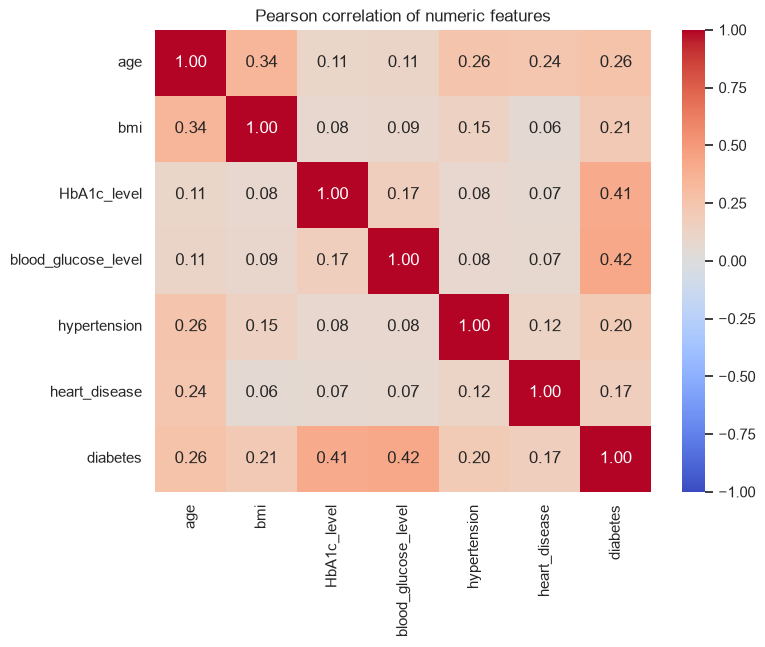

In [11]:
num_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level", "hypertension", "heart_disease", TARGET]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric features")
save_fig(fig, FIGURES_DIR / "eda_correlation_heatmap.png");

Blood glucose (r ≈ 0.42) and HbA1c (r ≈ 0.41) have the strongest linear association with diabetes, followed by age (0.27), BMI (0.22), hypertension (0.20) and heart disease (0.17). Predictors are only weakly correlated with each other, so multicollinearity is limited among the raw features (the engineered interaction terms are, by construction, correlated with their components).

## EDA summary

1. **Clean, mostly complete data** — duplicates and the tiny "Other" gender group removed; "No Info" smoking kept as a category.
2. **Imbalanced target (8.8%)** — evaluate with PR-AUC, sensitivity/precision and calibration, not accuracy.
3. **HbA1c and glucose dominate**, and partly *define* the label — interpret headline performance with care.
4. **Age, BMI, hypertension and heart disease** are meaningful secondary risk factors and form the basis of a lab-free screening model.